# K Nearest Neighbors with Python

You've been given a classified data set from a company! They've hidden the feature column names but have given you the data and the target classes.

We'll try to use KNN to create a model that directly predicts a class for a new data point based off of the features.

Let's grab it and use it!

## Import Libraries



In [ ]:
# WHAT: Import necessary core data science and visualization libraries.
# HOW: Use 'import ... as ...' to assign short aliases for easy coding.
# WHY:
#   - pandas (pd): To load and manipulate the dataset like a spreadsheet/table.
#   - numpy (np): To perform numerical operations.
#   - matplotlib & seaborn: To plot graphs and visualize the error rates.
#   - %matplotlib inline: Ensures the plots display directly inside the notebook cells.
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

## Get the Data

Set index_col=0 to use the first column as the index.

In [ ]:
# WHAT: Load the data from a file or download it from a web link if missing.
# HOW: Check if "Classified Data" exists locally. If not, pull it from GitHub using pd.read_csv() and save it.
# WHY: We need to load our dataset into memory as a Pandas DataFrame ('df') to train our model.
#      index_col=0 sets the first column (containing row numbers) as the index so it doesn't mess with features.
import pandas as pd
import os

file_name = "Classified Data"
if not os.path.exists(file_name):
    url = "https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Classified%20Data"
    df = pd.read_csv(url, index_col=0)
    df.to_csv(file_name)
else:
    df = pd.read_csv(file_name, index_col=0)

In [ ]:
import os
print(os.listdir('.'))

['.config', 'Classified Data', 'sample_data']


In [ ]:
df.head()

,WTT,PTI,EQW,SBI,LQE,QWG,FDJ,PJF,HQE,NXJ,TARGET CLASS
0,0.913917,1.162073,0.567946,0.755464,0.780862,0.352608,0.759697,0.643798,0.879422,1.231409,1
1,0.635632,1.003722,0.535342,0.825645,0.924109,0.648450,0.675334,1.013546,0.621552,1.492702,0
2,0.721360,1.201493,0.921990,0.855595,1.526629,0.720781,1.626351,1.154483,0.957877,1.285597,0
3,1.234204,1.386726,0.653046,0.825624,1.142504,0.875128,1.409708,1.380003,1.522692,1.153093,1
4,1.279491,0.949750,0.627280,0.668976,1.232537,0.703727,1.115596,0.646691,1.463812,1.419167,1


## Standardize the Variables

Because the KNN classifier predicts the class of a given test observation by identifying the observations that are nearest to it, the scale of the variables matters. Any variables that are on a large scale will have a much larger effect on the distance between the observations, and hence on the KNN classifier, than variables that are on a small scale.

In [ ]:
# WHAT: Import the StandardScaler tool.
# HOW: From Scikit-Learn's preprocessing submodule.
# WHY: KNN works by measuring distances between points. If one feature has huge values (e.g., 0-1000)
#      and another has small values (e.g., 0-1), the larger one will dominate the distance calculations.
#      Scaling ensures all features contribute equally (gives them mean=0 and variance=1).
from sklearn.preprocessing import StandardScaler

In [ ]:
# WHAT: Create an instance of the StandardScaler object.
# HOW: Assign it to a variable named 'scaler'.
# WHY: We must initialize this object before we can fit it to our specific dataset's parameters.
scaler = StandardScaler()

In [ ]:
# WHAT: Compute (fit) the mean and standard deviation of each feature.
# HOW: Pass df excluding the 'TARGET CLASS' column (using drop) because we only scale features, never the target label!
# WHY: This calculates the scaling formulas (subtraction and division values) for each column to prepare them for normalization.
scaler.fit(df.drop('TARGET CLASS',axis=1))

StandardScaler()

In [ ]:
# WHAT: Standardize (scale) the actual values.
# HOW: Call scaler.transform() on the features to center them around 0 with a standard deviation of 1.
# WHY: It applies the calculated scaling formula to our data, converting them into standard scale values.
scaled_features = scaler.transform(df.drop('TARGET CLASS',axis=1))

In [ ]:
# WHAT: Turn the scaled array back into a structured DataFrame and preview it.
# HOW: Use pd.DataFrame() and pass column names (excluding the final 'TARGET CLASS' name).
# WHY: Converting it back to a Pandas DataFrame format makes the data clean, readable, and ready for model splitting.
df_feat = pd.DataFrame(scaled_features,columns=df.columns[:-1])
df_feat.head()

,WTT,PTI,EQW,SBI,LQE,QWG,FDJ,PJF,HQE,NXJ
0,-0.123542,0.185907,-0.913431,0.319629,-1.033637,-2.308375,-0.798951,-1.482368,-0.949719,-0.643314
1,-1.084836,-0.430348,-1.025313,0.625388,-0.444847,-1.152706,-1.129797,-0.202240,-1.828051,0.636759
2,-0.788702,0.339318,0.301511,0.755873,2.031693,-0.870156,2.599818,0.285707,-0.682494,-0.377850
3,0.982841,1.060193,-0.621399,0.625299,0.452820,-0.267220,1.750208,1.066491,1.241325,-1.026987
4,1.139275,-0.640392,-0.709819,-0.057175,0.822886,-0.936773,0.596782,-1.472352,1.040772,0.276510


## Train Test Split

In [ ]:
# WHAT: Import train_test_split.
# HOW: From Scikit-Learn's model selection library.
# WHY: To evaluate how well our model performs on unseen data, we must split our data:
#      some for training (to learn patterns) and some for testing (to check performance).
from sklearn.model_selection import train_test_split

In [ ]:
# WHAT: Divide the features and target class into training and testing sets.
# HOW: Pass scaled features and the target label. set 'test_size=0.30' (30% test, 70% train).
# WHY:
#   - X_train & y_train: Used to fit/train the model.
#   - X_test & y_test: Kept aside to test if the model's predictions are correct.
X_train, X_test, y_train, y_test = train_test_split(scaled_features,df['TARGET CLASS'],
                                                    test_size=0.30)

## Using KNN

Remember that we are trying to come up with a model to predict whether someone will TARGET CLASS or not. We'll start with k=1.

In [ ]:
# WHAT: Import the KNN classification model class.
# HOW: From Scikit-Learn's neighbors module.
# WHY: KNN works by assigning a class to a point based on the classes of its nearest neighbors.
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
# WHAT: Create a KNN model instance with K=1.
# HOW: Use 'n_neighbors=1' parameter.
# WHY: We start with a baseline of K=1 (predicting based on just the single closest neighbor) to see its performance first.
knn = KNeighborsClassifier(n_neighbors=1)

In [ ]:
# WHAT: Train the KNN model.
# HOW: Pass X_train (scaled features) and y_train (true classes) to knn.fit().
# WHY: The model maps the relationship between the features and the targets, remembering where points lie.
knn.fit(X_train,y_train)

KNeighborsClassifier(n_neighbors=1)

In [ ]:
# WHAT: Use the trained model to make predictions.
# HOW: Pass the unseen X_test features to the predict method.
# WHY: To see what classes (0 or 1) our model guesses for the test set, which we can compare to the actual labels.
pred = knn.predict(X_test)

## Predictions and Evaluations

Let's evaluate our KNN model!

In [ ]:
# WHAT: Import evaluation metric reports.
# HOW: From Scikit-Learn's metrics module.
# WHY: We need standard tools to calculate accuracy, precision, recall, and show correct/incorrect counts.
from sklearn.metrics import classification_report,confusion_matrix

In [ ]:
# WHAT: Generate and print a Confusion Matrix.
# HOW: Pass y_test (actual values) and pred (predicted values).
# WHY: It shows a table of:
#   - True Negatives (Top-Left), False Positives (Top-Right)
#   - False Negatives (Bottom-Left), True Positives (Bottom-Right)
#   This lets us see exactly how many predictions were correct versus incorrect.
print(confusion_matrix(y_test,pred))

[[120  17]
 [ 11 152]]


In [ ]:
# WHAT: Display a comprehensive summary of classification metrics.
# HOW: Use classification_report(y_test, pred).
# WHY: It lists crucial performance scores:
#   - Precision: Out of all predicted positives, how many were actually positive?
#   - Recall: Out of all actual positives, how many did we successfully find?
#   - F1-Score: Harmonic mean of precision and recall (good overall metric).
#   - Accuracy: Total correct predictions over total predictions.
print(classification_report(y_test,pred))

              precision    recall  f1-score   support

           0       0.92      0.88      0.90       137
           1       0.90      0.93      0.92       163

    accuracy                           0.91       300
   macro avg       0.91      0.90      0.91       300
weighted avg       0.91      0.91      0.91       300



## Choosing a K Value

Let's go ahead and use the elbow method to pick a good K Value:

In [ ]:
# WHAT: Use the "Elbow Method" to find the best K value.
# HOW: Run a loop training KNN with K from 1 to 39, find predictions, and save the error rate (percentage of wrong predictions).
# WHY: K=1 might be noise-sensitive. We want to test different values of K to find the optimal point where error is minimized.
error_rate = []

for i in range(1,40):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(X_train,y_train)
    pred_i = knn.predict(X_test)
    error_rate.append(np.mean(pred_i != y_test))

Text(0, 0.5, 'Error Rate')

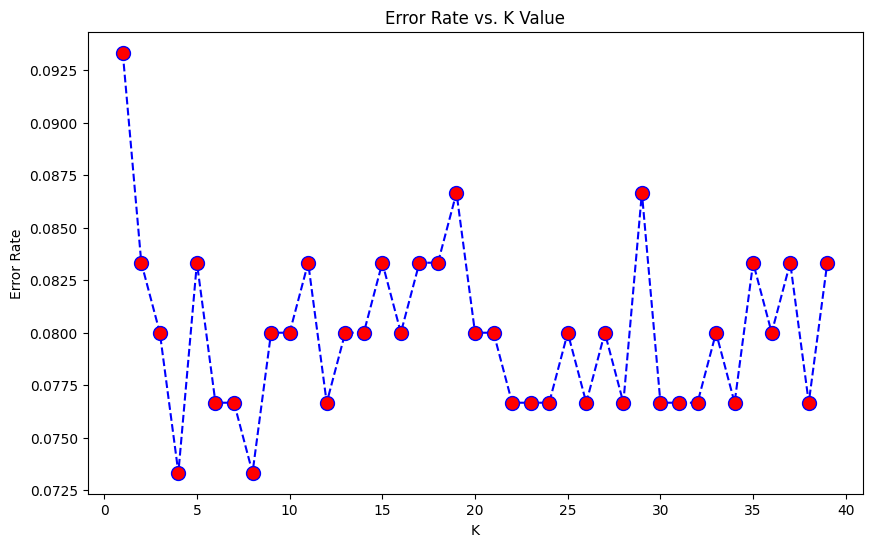

In [ ]:
# WHAT: Visualize the error rates across different K values.
# HOW: Plot K values on the X-axis and error rates on the Y-axis.
# WHY: Visualizing this curve allows us to spot the "elbow"—the point where the error rate drops and flattens out.
#      This helps us pick the most stable and accurate K value.
plt.figure(figsize=(10,6))
plt.plot(range(1,40),error_rate,color='blue', linestyle='dashed', marker='o',
         markerfacecolor='red', markersize=10)
plt.title('Error Rate vs. K Value')
plt.xlabel('K')
plt.ylabel('Error Rate')

Here we can see that that after arouns K>23 the error rate just tends to hover around 0.06-0.05 Let's retrain the model with that and check the classification report!

In [ ]:
# WHAT: Print baseline metrics for K=1 for comparison.
# HOW: Train and test using K=1, then output the metrics.
# WHY: Serves as our benchmark so we can compare and prove that choosing a better K (like K=23) actually improves the model.
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train,y_train)
pred = knn.predict(X_test)

print('WITH K=1')
print('\n')
print(confusion_matrix(y_test,pred))
print('\n')
print(classification_report(y_test,pred))

WITH K=1


[[120  17]
 [ 11 152]]


              precision    recall  f1-score   support

           0       0.92      0.88      0.90       137
           1       0.90      0.93      0.92       163

    accuracy                           0.91       300
   macro avg       0.91      0.90      0.91       300
weighted avg       0.91      0.91      0.91       300



In [ ]:
# WHAT: Retrain and evaluate the model using the optimal K value (K=23).
# HOW: Re-instantiate KNN with n_neighbors=23, fit on train data, predict, and output metrics.
# WHY: This demonstrates the final optimized model. You will see higher precision, recall, and overall accuracy compared to K=1.
knn = KNeighborsClassifier(n_neighbors=23)
knn.fit(X_train,y_train)
pred = knn.predict(X_test)

print('WITH K=23')
print('\n')
print(confusion_matrix(y_test,pred))
print('\n')
print(classification_report(y_test,pred))

WITH K=23


[[121  16]
 [  7 156]]


              precision    recall  f1-score   support

           0       0.95      0.88      0.91       137
           1       0.91      0.96      0.93       163

    accuracy                           0.92       300
   macro avg       0.93      0.92      0.92       300
weighted avg       0.92      0.92      0.92       300

